
# 20 — Marginal context-gain kernels and the origin of CLP compressibility

Notebook 19 showed that the dense context-length probing (CLP) profile

\[
D_{256}=(L_8,L_9,\ldots,L_{256})
\]

is extremely low-dimensional for both Qwen3-0.6B and GPT-2, and that roughly four
train-only principal components are stably non-inferior to the full 249-coordinate
representation for GPT-vs-Claude attribution.

This notebook asks for a **mathematical cause** before attempting scorer-internal
mechanistic analysis.

## Exact finite-difference decomposition

Define the adjacent context-length gain

\[
m_x(d)=L_{d-1}(x)-L_d(x),\qquad d=9,\ldots,256.
\]

This is the finite difference of the CLP loss curve. It should be interpreted as the
marginal effect of increasing the *available context length* from \(d-1\) to \(d\),
not as the causal contribution of one uniquely identified source token.

By telescoping,

\[
L_k(x)-L_{256}(x)
=
\sum_{d=k+1}^{256}m_x(d).
\]

Let

\[
M_{x,d}=m_x(d)
\]

be the document-by-distance marginal-gain matrix, and let \(C\) be the discrete
cumulative-sum operator. Then the endpoint-normalized CLP shape satisfies exactly

\[
S = MC.
\]

The raw dense profile can therefore be written schematically as

\[
L = b\mathbf{1}^{\top}+MC,
\]

where \(b_x=L_{256}(x)\).

This exposes three possible sources of the low dimensionality found in notebook 19:

1. **Global loss level:** \(b\mathbf{1}^{\top}\) is rank one.
2. **Integration/smoothing:** the cumulative operator \(C\) suppresses high-frequency
   variation and itself has a decaying singular spectrum.
3. **Scorer-response structure:** the marginal matrix \(M\) may itself be close to
   low rank,

   \[
   m_x(d)\approx\sum_{r=1}^{R}a_{x,r}\kappa_r(d),
   \]

   corresponding to a small number of reusable distance-response kernels.

The goal is to determine how much each mechanism contributes.

## Secondary parametric hypothesis

Notebook 12 found that log-context approximations reconstruct dense CLP much better
than ordinary linear-context approximations. One possible mechanism is a power-law
marginal kernel,

\[
\kappa(d)\propto d^{-\alpha}.
\]

For \(\alpha=1\),

\[
\sum_{d=k+1}^{N}\frac{1}{d}
\approx \log\frac{N}{k},
\]

which naturally produces an approximately log-linear CLP shape. We test this
hypothesis against an exponential-decay alternative rather than assuming it is true.

No new language-model inference is required. Everything below uses the saved dense
CLP curves from notebooks 12--19.


In [1]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "experiments" else cwd
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

QWEN_PATH = RESULTS / "cifka_dense_clp_qwen06b.parquet"
GPT2_PATH = RESULTS / "cifka_dense_clp_gpt2.parquet"

assert QWEN_PATH.exists(), QWEN_PATH
assert GPT2_PATH.exists(), GPT2_PATH

MIN_K, MAX_K = 8, 256

L_COLS = [f"L_{k}" for k in range(MIN_K, MAX_K + 1)]
DISTANCES = np.arange(MIN_K + 1, MAX_K + 1)   # d = 9,...,256
SHAPE_K = np.arange(MIN_K, MAX_K)             # k = 8,...,255

print("ROOT:", ROOT)
print("Dense CLP coordinates:", len(L_COLS))
print("Finite-difference coordinates:", len(DISTANCES))


ROOT: ..
Dense CLP coordinates: 249
Finite-difference coordinates: 248


In [2]:

def prepare(path, scorer):
    df = pd.read_parquet(path).copy()
    df = df.dropna(subset=L_COLS)

    pairs = df.groupby("pair_id")["generator"].agg(["size", "nunique"])
    ok = pairs.index[(pairs["size"] == 2) & (pairs["nunique"] == 2)]
    df = df[df["pair_id"].isin(ok)].copy()

    df["scorer"] = scorer
    return df


qwen = prepare(QWEN_PATH, "Qwen3-0.6B")
gpt2 = prepare(GPT2_PATH, "GPT-2")

for scorer, df in [("Qwen3-0.6B", qwen), ("GPT-2", gpt2)]:
    print(scorer, "pairs", df["pair_id"].nunique(), "docs", len(df))
    display(df.groupby(["domain", "generator"]).size())

q_manifest = set(
    qwen[["pair_id", "generator"]].itertuples(index=False, name=None)
)
g_manifest = set(
    gpt2[["pair_id", "generator"]].itertuples(index=False, name=None)
)

print("same scorer document manifest:", q_manifest == g_manifest)
assert q_manifest == g_manifest


Qwen3-0.6B pairs 146 docs 292


domain  generator
essay   claude       46
        gpt          46
reuter  claude       49
        gpt          49
wp      claude       51
        gpt          51
dtype: int64

GPT-2 pairs 146 docs 292


domain  generator
essay   claude       46
        gpt          46
reuter  claude       49
        gpt          49
wp      claude       51
        gpt          51
dtype: int64

same scorer document manifest: True



## 1. Construct the marginal-gain matrix and verify the exact identity

For each document,

\[
m(d)=L_{d-1}-L_d.
\]

We construct

\[
M\in\mathbb{R}^{n\times248}
\]

and the endpoint-normalized shape

\[
S_k=L_k-L_{256},
\qquad k=8,\ldots,255.
\]

The cumulative operator \(C\in\mathbb{R}^{248\times248}\) is defined by

\[
C_{j,i}=\mathbf{1}[j\ge i],
\]

under the ordered coordinates \(d=9,\ldots,256\) and \(k=8,\ldots,255\). We first
verify numerically that

\[
S=MC
\]

to floating-point precision.


In [3]:

def matrices(df):
    L = df[L_COLS].to_numpy(dtype=float)

    # m(d) = L_{d-1} - L_d for d=9,...,256
    M = L[:, :-1] - L[:, 1:]

    # S(k) = L_k - L_256 for k=8,...,255
    S = L[:, :-1] - L[:, [-1]]

    return L, M, S


# C[j, i] = 1 if j >= i.
D = len(DISTANCES)
C = np.tril(np.ones((D, D), dtype=float))

matrix_cache = {}

for scorer, df in [("Qwen3-0.6B", qwen), ("GPT-2", gpt2)]:
    L, M, S = matrices(df)
    S_from_M = M @ C

    err = np.abs(S - S_from_M)

    matrix_cache[scorer] = {
        "df": df,
        "L": L,
        "M": M,
        "S": S,
    }

    print(
        scorer,
        "| max telescoping error:", err.max(),
        "| mean error:", err.mean(),
    )

    assert np.allclose(S, S_from_M, atol=1e-10, rtol=1e-10)


Qwen3-0.6B | max telescoping error: 0.0 | mean error: 0.0
GPT-2 | max telescoping error: 0.0 | mean error: 0.0



## 2. The cumulative operator already has a decaying spectrum

Even if the marginal-gain vector \(m(d)\) contains high-frequency variation, the map

\[
m \mapsto S
\]

integrates it. Discrete integration is a smoothing operator: its singular values
decay rather than remaining flat.

This does **not** prove that observed CLP low rank is merely an artifact of the
measurement construction. It gives an operator-level mechanism that we can compare
against the empirical marginal matrix in later sections.


In [4]:

op_sv = np.linalg.svd(C, compute_uv=False)
op_energy = np.cumsum(op_sv ** 2) / np.sum(op_sv ** 2)

operator_summary = pd.DataFrame({
    "component": np.arange(1, len(op_sv) + 1),
    "singular_value": op_sv,
    "relative_singular_value": op_sv / op_sv[0],
    "cumulative_energy": op_energy,
})

operator_summary.to_csv(
    RESULTS / "clp_cumulative_operator_spectrum.csv",
    index=False,
)

for threshold in [0.90, 0.95, 0.99]:
    r = int(np.searchsorted(op_energy, threshold) + 1)
    print(f"operator rank for {threshold:.0%} Frobenius energy:", r)

display(operator_summary.head(10))


operator rank for 90% Frobenius energy: 2
operator rank for 95% Frobenius energy: 5
operator rank for 99% Frobenius energy: 21


,component,singular_value,relative_singular_value,cumulative_energy
0,1,158.200277,1.000000,0.810575
1,2,52.734128,0.333338,0.900642
2,3,31.641320,0.200008,0.933067
3,4,22.601846,0.142869,0.949612
4,5,17.580150,0.111126,0.959622
5,6,14.384717,0.090927,0.966324
6,7,12.172656,0.076945,0.971123
7,8,10.550619,0.066692,0.974728
8,9,9.310362,0.058852,0.977536
9,10,8.331323,0.052663,0.979784


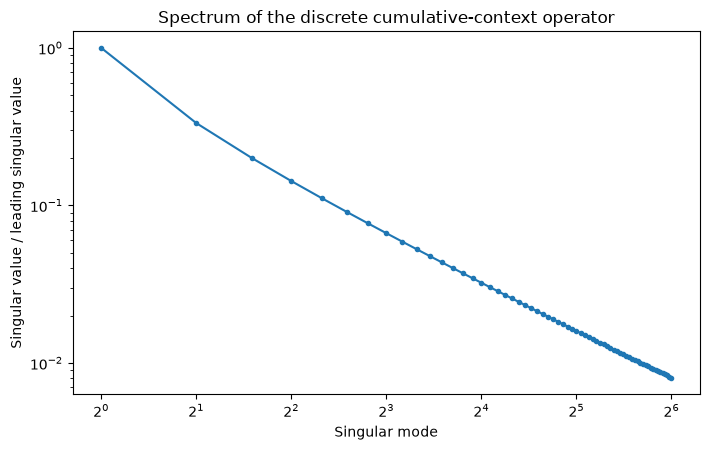

In [5]:

fig, ax = plt.subplots(figsize=(7.2, 4.6))

show = operator_summary[operator_summary["component"] <= 64]
ax.plot(
    show["component"],
    show["relative_singular_value"],
    marker="o",
    markersize=3,
)

ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_xlabel("Singular mode")
ax.set_ylabel("Singular value / leading singular value")
ax.set_title("Spectrum of the discrete cumulative-context operator")
fig.tight_layout()

fig.savefig(
    FIGURES / "clp_cumulative_operator_spectrum.png",
    dpi=220,
    bbox_inches="tight",
)
fig.savefig(
    FIGURES / "clp_cumulative_operator_spectrum.pdf",
    bbox_inches="tight",
)
plt.show()



## 3. Where does the observed low rank appear?

We compare four objects:

- `RawL`: \(L_8,\ldots,L_{256}\);
- `Shape`: \(L_k-L_{256}\);
- `Marginal`: \(L_{d-1}-L_d\);
- `MarginalSmooth8`: an 8-distance moving-average version of the marginal curve,
  used only as a noise/smoothness diagnostic.

For each representation we compute centered covariance eigenvalues and report:

\[
d_{\rm PR}
=
\frac{(\sum_i\lambda_i)^2}{\sum_i\lambda_i^2},
\]

together with the dimensions required for 90%, 95%, and 99% explained variance.

The central diagnostic is whether `Marginal` is already low-dimensional. If it is
not, while `Shape` is, then cumulative integration itself is doing substantial
dimensionality reduction. If both are low-dimensional, then the scorer response has
additional few-kernel structure beyond the integration operator.


In [6]:

def moving_average_rows(X, width=8):
    # Same-size centered moving average along the distance axis.
    kernel = np.ones(width, dtype=float) / width
    return np.vstack([
        np.convolve(row, kernel, mode="same")
        for row in X
    ])


def spectrum_stats(X):
    X = np.asarray(X, dtype=float)
    Xc = X - X.mean(axis=0, keepdims=True)

    # PCA eigenvalues via singular values.
    sv = np.linalg.svd(Xc, full_matrices=False, compute_uv=False)
    eig = (sv ** 2) / max(len(X) - 1, 1)

    total = eig.sum()
    evr = eig / total
    cum = np.cumsum(evr)

    participation_ratio = (eig.sum() ** 2) / np.square(eig).sum()

    return {
        "participation_ratio": participation_ratio,
        "r90": int(np.searchsorted(cum, 0.90) + 1),
        "r95": int(np.searchsorted(cum, 0.95) + 1),
        "r99": int(np.searchsorted(cum, 0.99) + 1),
        "evr": evr,
        "cum": cum,
    }


rank_rows = []
rank_spectra = []

for scorer, pack in matrix_cache.items():
    L = pack["L"]
    M = pack["M"]
    S = pack["S"]

    reps = {
        "RawL": L,
        "Shape": S,
        "Marginal": M,
        "MarginalSmooth8": moving_average_rows(M, width=8),
    }

    for representation, X in reps.items():
        st = spectrum_stats(X)

        rank_rows.append({
            "scorer": scorer,
            "representation": representation,
            "n_coordinates": X.shape[1],
            "participation_ratio": st["participation_ratio"],
            "r90": st["r90"],
            "r95": st["r95"],
            "r99": st["r99"],
        })

        for i, (evr, cum) in enumerate(zip(st["evr"], st["cum"]), start=1):
            rank_spectra.append({
                "scorer": scorer,
                "representation": representation,
                "component": i,
                "evr": evr,
                "cumulative_evr": cum,
            })

rank_summary = pd.DataFrame(rank_rows)
rank_spectrum = pd.DataFrame(rank_spectra)

rank_summary.to_csv(
    RESULTS / "clp_marginal_vs_integrated_rank_summary.csv",
    index=False,
)
rank_spectrum.to_csv(
    RESULTS / "clp_marginal_vs_integrated_spectrum.csv",
    index=False,
)

display(rank_summary)


,scorer,representation,n_coordinates,participation_ratio,r90,r95,r99
0,Qwen3-0.6B,RawL,249,1.078199,1,1,3
1,Qwen3-0.6B,Shape,248,1.850152,3,6,20
2,Qwen3-0.6B,Marginal,248,50.397899,89,120,176
3,Qwen3-0.6B,MarginalSmooth8,248,10.507402,28,44,90
4,GPT-2,RawL,249,1.130509,1,2,4
5,GPT-2,Shape,248,1.726089,3,5,17
6,GPT-2,Marginal,248,59.508042,92,120,175
7,GPT-2,MarginalSmooth8,248,11.527575,26,41,85


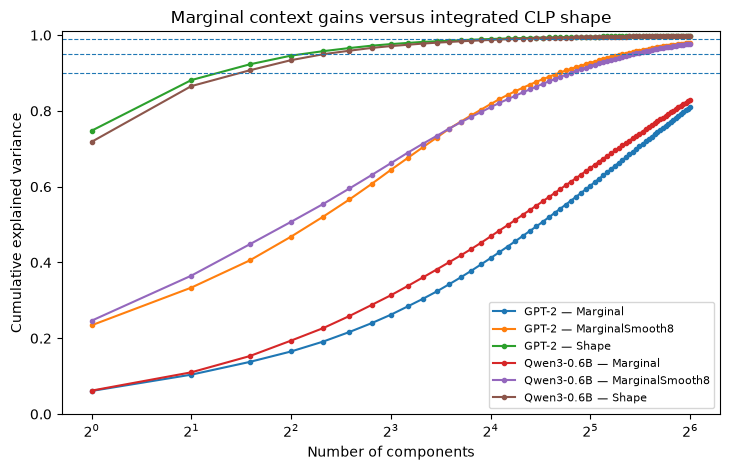

In [7]:

fig, ax = plt.subplots(figsize=(7.4, 4.8))

for (scorer, representation), g in rank_spectrum.groupby(
    ["scorer", "representation"]
):
    if representation not in ["Shape", "Marginal", "MarginalSmooth8"]:
        continue

    g = g[g["component"] <= 64]
    ax.plot(
        g["component"],
        g["cumulative_evr"],
        marker="o",
        markersize=3,
        label=f"{scorer} — {representation}",
    )

for y in [0.90, 0.95, 0.99]:
    ax.axhline(y, linestyle="--", linewidth=0.8)

ax.set_xscale("log", base=2)
ax.set_xlabel("Number of components")
ax.set_ylabel("Cumulative explained variance")
ax.set_title("Marginal context gains versus integrated CLP shape")
ax.set_ylim(0, 1.01)
ax.legend(fontsize=8)
fig.tight_layout()

fig.savefig(
    FIGURES / "clp_marginal_vs_integrated_rank.png",
    dpi=220,
    bbox_inches="tight",
)
fig.savefig(
    FIGURES / "clp_marginal_vs_integrated_rank.pdf",
    bbox_inches="tight",
)
plt.show()



## 4. Operator-only null: destroy cross-distance document structure

The exact identity \(S=MC\) means a low-dimensional \(S\) can arise from either:

- the integration operator \(C\), or
- correlated structure across the columns of \(M\).

To separate them, independently permute the documents **within each distance column**
of \(M\). This preserves the marginal distribution and variance of every
\(m(d)\), but destroys document-level cross-distance covariance.

For each permutation we integrate the shuffled marginal matrix with the same \(C\)
and measure the participation-ratio dimension of the resulting shape.

If the observed shape is substantially lower-dimensional than this null, then the
scorer response contains genuine cross-distance structure beyond the smoothing
imposed by cumulative integration.


In [8]:

NULL_REPS = 100
NULL_SEED = 2001

def participation_ratio_centered(X):
    Xc = X - X.mean(axis=0, keepdims=True)
    cov = (Xc.T @ Xc) / max(len(Xc) - 1, 1)

    # PR can be computed from traces without an eigendecomposition:
    # (sum lambda)^2 / sum lambda^2.
    tr = np.trace(cov)
    tr2 = np.square(cov).sum()
    return (tr ** 2) / tr2


null_rows = []

for scorer, pack in matrix_cache.items():
    M = pack["M"]
    S = pack["S"]

    observed_pr = participation_ratio_centered(S)

    rng = np.random.RandomState(NULL_SEED)

    for rep in range(NULL_REPS):
        Mp = np.empty_like(M)

        for j in range(M.shape[1]):
            Mp[:, j] = M[rng.permutation(M.shape[0]), j]

        Sp = Mp @ C

        null_rows.append({
            "scorer": scorer,
            "rep": rep,
            "shape_participation_ratio": participation_ratio_centered(Sp),
        })

    vals = [
        r["shape_participation_ratio"]
        for r in null_rows
        if r["scorer"] == scorer
    ]

    print(
        scorer,
        "| observed shape PR:", round(observed_pr, 4),
        "| null median:", round(float(np.median(vals)), 4),
        "| null 2.5–97.5%:",
        (
            round(float(np.quantile(vals, 0.025)), 4),
            round(float(np.quantile(vals, 0.975)), 4),
        ),
    )

null_df = pd.DataFrame(null_rows)
null_df.to_csv(
    RESULTS / "clp_operator_only_null.csv",
    index=False,
)


Qwen3-0.6B | observed shape PR: 1.8502 | null median: 2.015 | null 2.5–97.5%: (1.8097, 2.2078)
GPT-2 | observed shape PR: 1.7261 | null median: 1.9216 | null 2.5–97.5%: (1.7517, 2.1193)


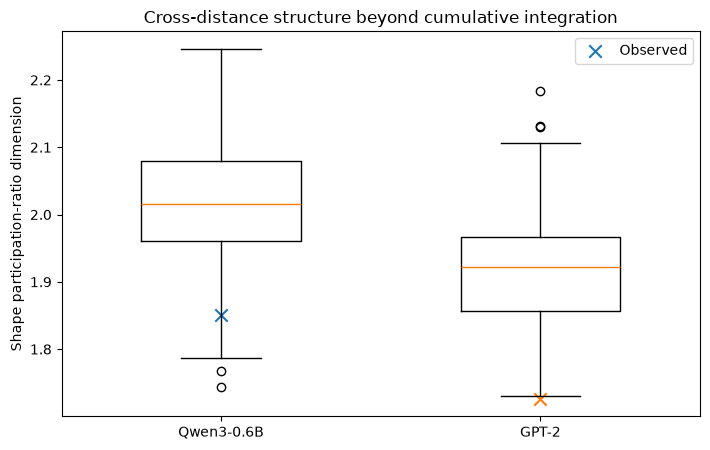

In [9]:

fig, ax = plt.subplots(figsize=(7.2, 4.6))

positions = []
data = []
labels = []

for i, scorer in enumerate(["Qwen3-0.6B", "GPT-2"]):
    vals = null_df.loc[
        null_df["scorer"] == scorer,
        "shape_participation_ratio"
    ].to_numpy()

    positions.append(i + 1)
    data.append(vals)
    labels.append(scorer)

    observed = participation_ratio_centered(
        matrix_cache[scorer]["S"]
    )
    ax.scatter([i + 1], [observed], marker="x", s=80, label=(
        "Observed" if i == 0 else None
    ))

ax.boxplot(data, positions=positions, widths=0.5)
ax.set_xticks(positions)
ax.set_xticklabels(labels)
ax.set_ylabel("Shape participation-ratio dimension")
ax.set_title("Cross-distance structure beyond cumulative integration")
ax.legend()
fig.tight_layout()

fig.savefig(
    FIGURES / "clp_operator_null_dimension.png",
    dpi=220,
    bbox_inches="tight",
)
fig.savefig(
    FIGURES / "clp_operator_null_dimension.pdf",
    bbox_inches="tight",
)
plt.show()



## 5. Empirical marginal kernels from SVD

If

\[
m_x(d)\approx\sum_{r=1}^{R}a_{x,r}\kappa_r(d),
\]

then the right singular vectors of the centered marginal matrix provide empirical
distance kernels \(\kappa_r(d)\).

We inspect:

1. the first few marginal kernels;
2. their integrated forms;
3. how much of the observed CLP shape can be reconstructed after truncating the
   marginal matrix to rank \(R\).

This is an empirical decomposition, not yet a transformer-internal mechanism.


In [10]:

R_RECON = [1, 2, 3, 4, 6, 8, 16, 32]

kernel_rows = []
recon_rows = []

for scorer, pack in matrix_cache.items():
    M = pack["M"]
    S = pack["S"]

    # Center marginal curves across documents, but retain the empirical mean
    # exactly so low-rank reconstruction concerns document-to-document structure.
    mu = M.mean(axis=0, keepdims=True)
    Mc = M - mu

    U, sv, Vt = np.linalg.svd(Mc, full_matrices=False)

    for r in range(min(3, len(sv))):
        kernel = Vt[r]
        integrated = kernel @ C

        # Fix arbitrary SVD sign so the integrated short-context end is positive
        # whenever possible. This is only for plot readability.
        if integrated[0] < 0:
            kernel = -kernel
            integrated = -integrated

        for d, val in zip(DISTANCES, kernel):
            kernel_rows.append({
                "scorer": scorer,
                "component": r + 1,
                "object": "marginal_kernel",
                "x": int(d),
                "value": val,
            })

        for k, val in zip(SHAPE_K, integrated):
            kernel_rows.append({
                "scorer": scorer,
                "component": r + 1,
                "object": "integrated_kernel",
                "x": int(k),
                "value": val,
            })

    denom_M = np.square(M).mean()
    denom_S = np.square(S).mean()

    for r in R_RECON:
        Mr = mu + (U[:, :r] * sv[:r]) @ Vt[:r]
        Sr = Mr @ C

        marginal_nrmse = np.sqrt(
            np.square(M - Mr).mean() / denom_M
        )
        shape_nrmse = np.sqrt(
            np.square(S - Sr).mean() / denom_S
        )

        recon_rows.append({
            "scorer": scorer,
            "r": r,
            "marginal_nrmse": marginal_nrmse,
            "shape_nrmse_after_integration": shape_nrmse,
            "shape_energy_recovered":
                1.0 - np.square(S - Sr).sum() / np.square(S).sum(),
        })

kernels = pd.DataFrame(kernel_rows)
reconstruction = pd.DataFrame(recon_rows)

kernels.to_csv(
    RESULTS / "clp_empirical_marginal_kernels.csv",
    index=False,
)
reconstruction.to_csv(
    RESULTS / "clp_marginal_rank_reconstruction.csv",
    index=False,
)

display(reconstruction)


,scorer,r,marginal_nrmse,shape_nrmse_after_integration,shape_energy_recovered
0,Qwen3-0.6B,1,0.715612,0.333632,0.888690
1,Qwen3-0.6B,2,0.696935,0.332214,0.889634
2,Qwen3-0.6B,3,0.679981,0.329045,0.891729
3,Qwen3-0.6B,4,0.663357,0.327633,0.892657
4,Qwen3-0.6B,6,0.636096,0.323250,0.895509
5,Qwen3-0.6B,8,0.612177,0.315598,0.900398
6,Qwen3-0.6B,16,0.538574,0.292368,0.914521
7,Qwen3-0.6B,32,0.437518,0.247737,0.938626
8,GPT-2,1,0.766493,0.386576,0.850559
9,GPT-2,2,0.748726,0.385803,0.851156


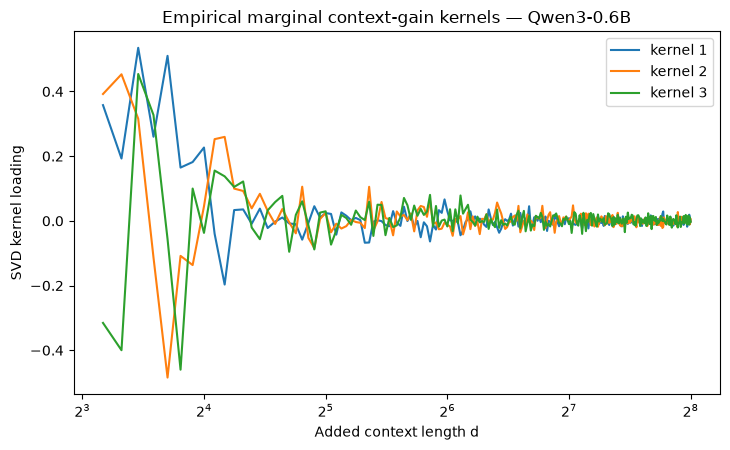

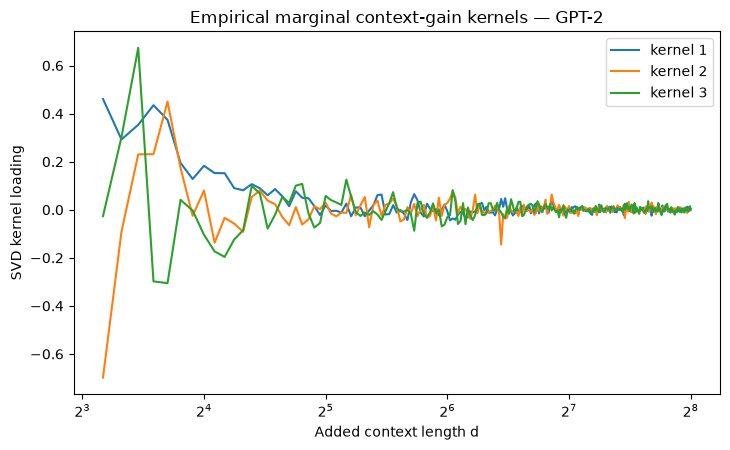

In [11]:

for scorer in ["Qwen3-0.6B", "GPT-2"]:
    fig, ax = plt.subplots(figsize=(7.4, 4.6))

    sub = kernels[
        (kernels["scorer"] == scorer) &
        (kernels["object"] == "marginal_kernel")
    ]

    for component, g in sub.groupby("component"):
        ax.plot(
            g["x"],
            g["value"],
            label=f"kernel {component}",
        )

    ax.set_xscale("log", base=2)
    ax.set_xlabel("Added context length d")
    ax.set_ylabel("SVD kernel loading")
    ax.set_title(f"Empirical marginal context-gain kernels — {scorer}")
    ax.legend()
    fig.tight_layout()

    stem = scorer.lower().replace(".", "").replace("-", "_")
    fig.savefig(
        FIGURES / f"clp_marginal_kernels_{stem}.png",
        dpi=220,
        bbox_inches="tight",
    )
    fig.savefig(
        FIGURES / f"clp_marginal_kernels_{stem}.pdf",
        bbox_inches="tight",
    )
    plt.show()


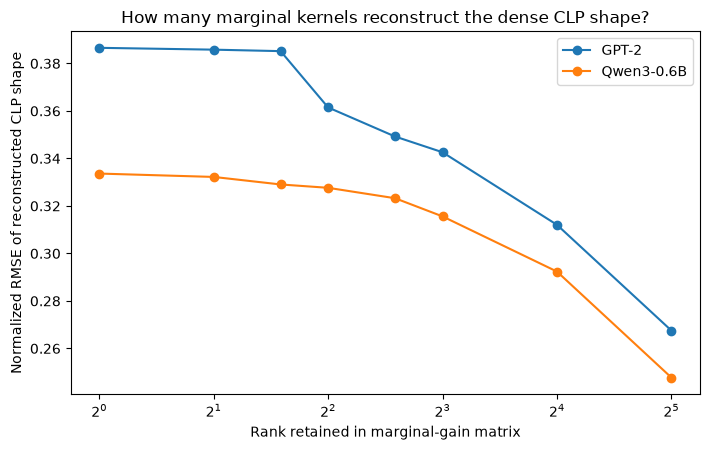

In [12]:

fig, ax = plt.subplots(figsize=(7.2, 4.6))

for scorer, g in reconstruction.groupby("scorer"):
    ax.plot(
        g["r"],
        g["shape_nrmse_after_integration"],
        marker="o",
        label=scorer,
    )

ax.set_xscale("log", base=2)
ax.set_xlabel("Rank retained in marginal-gain matrix")
ax.set_ylabel("Normalized RMSE of reconstructed CLP shape")
ax.set_title("How many marginal kernels reconstruct the dense CLP shape?")
ax.legend()
fig.tight_layout()

fig.savefig(
    FIGURES / "clp_marginal_rank_shape_reconstruction.png",
    dpi=220,
    bbox_inches="tight",
)
fig.savefig(
    FIGURES / "clp_marginal_rank_shape_reconstruction.pdf",
    bbox_inches="tight",
)
plt.show()



## 6. Does a power-law kernel explain the log-context geometry?

We now test a constrained one-kernel model.

For a candidate exponent \(\alpha\), define the integrated power-law basis

\[
g_\alpha(k)
=
\sum_{d=k+1}^{256} d^{-\alpha}.
\]

For each document we fit only an amplitude \(a_x\):

\[
S_x(k)\approx a_x g_\alpha(k).
\]

Thus \(\alpha\) is shared across documents for a scorer; the document-specific
degree of freedom is only the amplitude.

We compare:

- \(\alpha=0\): constant marginal gain, producing a linear-in-\(k\) shape;
- \(\alpha=1\): harmonic marginal gain, producing approximately log-context shape;
- best shared power-law exponent;
- best shared exponential-decay kernel;
- rank-1 SVD reconstruction as a non-parametric one-dimensional oracle.

A power law is convincing only if it performs competitively with the one-dimensional
SVD oracle and beats the exponential alternative. Otherwise the low rank is real,
but the \(1/d^\alpha\) explanation is not.


In [13]:

def integrated_power_basis(alpha):
    w = DISTANCES.astype(float) ** (-alpha)
    return w @ C


def integrated_exp_basis(tau):
    w = np.exp(-DISTANCES.astype(float) / tau)
    return w @ C


def amplitude_fit_energy(S, basis):
    basis = np.asarray(basis, dtype=float)
    denom = float(basis @ basis)

    a = (S @ basis) / denom
    pred = a[:, None] * basis[None, :]

    sse = np.square(S - pred).sum()
    total = np.square(S).sum()

    return {
        "energy_recovered": 1.0 - sse / total,
        "nrmse": np.sqrt(sse / total),
        "amplitude": a,
    }


ALPHA_GRID = np.linspace(0.0, 3.0, 301)
TAU_GRID = np.geomspace(2.0, 1024.0, 301)

param_rows = []

for scorer, pack in matrix_cache.items():
    S = pack["S"]

    power_scores = []
    for alpha in ALPHA_GRID:
        fit = amplitude_fit_energy(S, integrated_power_basis(alpha))
        power_scores.append((fit["energy_recovered"], alpha, fit["nrmse"]))

    power_scores.sort(reverse=True)
    best_power = power_scores[0]

    exp_scores = []
    for tau in TAU_GRID:
        fit = amplitude_fit_energy(S, integrated_exp_basis(tau))
        exp_scores.append((fit["energy_recovered"], tau, fit["nrmse"]))

    exp_scores.sort(reverse=True)
    best_exp = exp_scores[0]

    for label, alpha in [
        ("power_alpha_0", 0.0),
        ("power_alpha_1", 1.0),
        ("power_best", best_power[1]),
    ]:
        fit = amplitude_fit_energy(S, integrated_power_basis(alpha))
        param_rows.append({
            "scorer": scorer,
            "model": label,
            "parameter": alpha,
            "shape_energy_recovered": fit["energy_recovered"],
            "shape_nrmse": fit["nrmse"],
        })

    fit_exp = amplitude_fit_energy(S, integrated_exp_basis(best_exp[1]))
    param_rows.append({
        "scorer": scorer,
        "model": "exponential_best",
        "parameter": best_exp[1],
        "shape_energy_recovered": fit_exp["energy_recovered"],
        "shape_nrmse": fit_exp["nrmse"],
    })

    # Uncentered rank-1 SVD oracle on S.
    U, sv, Vt = np.linalg.svd(S, full_matrices=False)
    S1 = (U[:, :1] * sv[:1]) @ Vt[:1]
    sse = np.square(S - S1).sum()
    total = np.square(S).sum()

    param_rows.append({
        "scorer": scorer,
        "model": "rank1_svd_oracle",
        "parameter": np.nan,
        "shape_energy_recovered": 1.0 - sse / total,
        "shape_nrmse": np.sqrt(sse / total),
    })

parametric = pd.DataFrame(param_rows)
parametric.to_csv(
    RESULTS / "clp_parametric_kernel_fits.csv",
    index=False,
)

display(parametric)


,scorer,model,parameter,shape_energy_recovered,shape_nrmse
0,Qwen3-0.6B,power_alpha_0,0.000000,0.788913,0.459443
1,Qwen3-0.6B,power_alpha_1,1.000000,0.937829,0.249342
2,Qwen3-0.6B,power_best,1.370000,0.962780,0.192924
3,Qwen3-0.6B,exponential_best,56.885932,0.945694,0.233036
4,Qwen3-0.6B,rank1_svd_oracle,NaN,0.962937,0.192518
5,GPT-2,power_alpha_0,0.000000,0.799746,0.447497
6,GPT-2,power_alpha_1,1.000000,0.937910,0.249180
7,GPT-2,power_best,1.290000,0.953659,0.215270
8,GPT-2,exponential_best,60.547689,0.946065,0.232239
9,GPT-2,rank1_svd_oracle,NaN,0.954734,0.212758


In [14]:

# Fit the best power-law exponent separately by scorer and generator as a
# heterogeneity diagnostic. This is exploratory; the scorer-wide fit above remains
# the primary parametric test.
heterogeneity_rows = []

for scorer, pack in matrix_cache.items():
    df = pack["df"]
    S_all = pack["S"]

    for generator in sorted(df["generator"].unique()):
        mask = (df["generator"].to_numpy() == generator)
        S = S_all[mask]

        scores = []
        for alpha in ALPHA_GRID:
            fit = amplitude_fit_energy(S, integrated_power_basis(alpha))
            scores.append((fit["energy_recovered"], alpha, fit["nrmse"]))

        scores.sort(reverse=True)
        best = scores[0]

        heterogeneity_rows.append({
            "scorer": scorer,
            "generator": generator,
            "best_alpha": best[1],
            "shape_energy_recovered": best[0],
            "shape_nrmse": best[2],
            "n_docs": int(mask.sum()),
        })

power_heterogeneity = pd.DataFrame(heterogeneity_rows)
power_heterogeneity.to_csv(
    RESULTS / "clp_powerlaw_generator_heterogeneity.csv",
    index=False,
)

display(power_heterogeneity)


,scorer,generator,best_alpha,shape_energy_recovered,shape_nrmse,n_docs
0,Qwen3-0.6B,claude,1.35,0.961422,0.196413,146
1,Qwen3-0.6B,gpt,1.39,0.964119,0.189424,146
2,GPT-2,claude,1.30,0.950144,0.223284,146
3,GPT-2,gpt,1.29,0.956667,0.208165,146


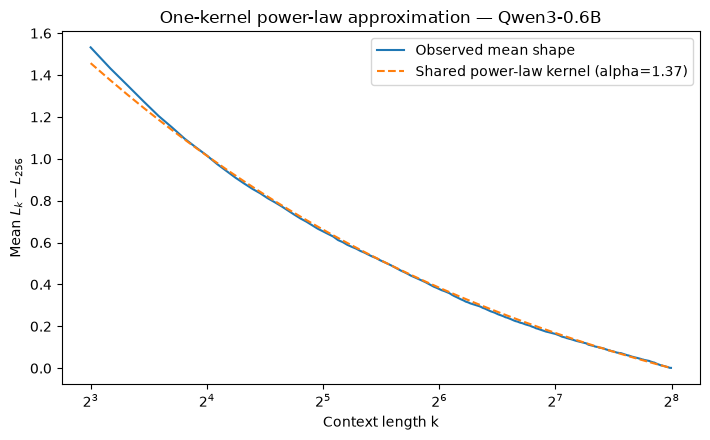

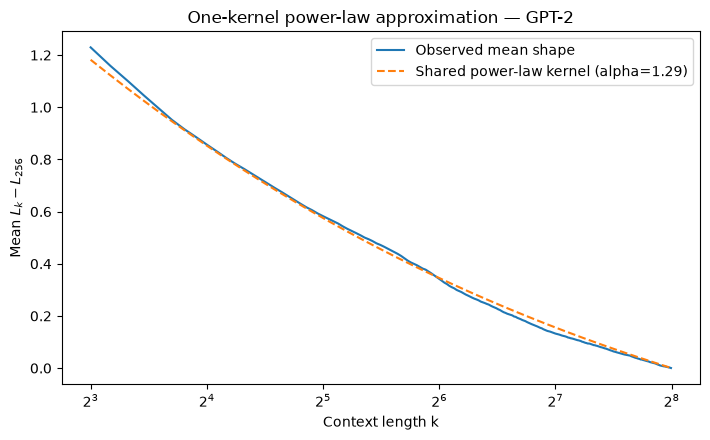

In [15]:

# Visual comparison of the mean observed endpoint-normalized shape with the
# best one-kernel power-law prediction.
for scorer, pack in matrix_cache.items():
    S = pack["S"]

    best = parametric[
        (parametric["scorer"] == scorer) &
        (parametric["model"] == "power_best")
    ].iloc[0]

    alpha = float(best["parameter"])
    basis = integrated_power_basis(alpha)
    fit = amplitude_fit_energy(S, basis)

    mean_observed = S.mean(axis=0)
    mean_pred = (
        fit["amplitude"].mean() * basis
    )

    fig, ax = plt.subplots(figsize=(7.2, 4.5))
    ax.plot(SHAPE_K, mean_observed, label="Observed mean shape")
    ax.plot(
        SHAPE_K,
        mean_pred,
        linestyle="--",
        label=f"Shared power-law kernel (alpha={alpha:.2f})",
    )

    ax.set_xscale("log", base=2)
    ax.set_xlabel("Context length k")
    ax.set_ylabel(r"Mean $L_k-L_{256}$")
    ax.set_title(f"One-kernel power-law approximation — {scorer}")
    ax.legend()
    fig.tight_layout()

    stem = scorer.lower().replace(".", "").replace("-", "_")
    fig.savefig(
        FIGURES / f"clp_powerlaw_shape_{stem}.png",
        dpi=220,
        bbox_inches="tight",
    )
    fig.savefig(
        FIGURES / f"clp_powerlaw_shape_{stem}.pdf",
        bbox_inches="tight",
    )
    plt.show()


In [16]:
# Direct test of the marginal power law after log-distance binning.

N_BINS = 16
edges = np.geomspace(
    DISTANCES.min(),
    DISTANCES.max() + 1,
    N_BINS + 1
)

rows = []

for scorer, pack in matrix_cache.items():
    M = pack["M"]

    mean_m = M.mean(axis=0)

    for i in range(N_BINS):
        mask = (
            (DISTANCES >= edges[i]) &
            (DISTANCES < edges[i + 1])
        )

        if not mask.any():
            continue

        d_mid = np.exp(
            np.mean(np.log(DISTANCES[mask]))
        )

        rows.append({
            "scorer": scorer,
            "bin": i,
            "d_mid": d_mid,
            "mean_marginal": mean_m[mask].mean(),
            "n_distances": mask.sum(),
        })

binned = pd.DataFrame(rows)
display(binned)

,scorer,bin,d_mid,mean_marginal,n_distances
0,Qwen3-0.6B,0,9.966555,0.086706,3
1,Qwen3-0.6B,1,12.489996,0.061094,2
2,Qwen3-0.6B,2,14.977745,0.044686,3
3,Qwen3-0.6B,3,18.466146,0.033553,4
4,Qwen3-0.6B,4,22.956423,0.021780,5
5,Qwen3-0.6B,5,28.448717,0.017769,6
6,Qwen3-0.6B,6,35.425861,0.011919,8
7,Qwen3-0.6B,7,43.924076,0.008833,9
8,Qwen3-0.6B,8,53.907203,0.007355,11
9,Qwen3-0.6B,9,66.377529,0.005878,14


In [17]:
fit_rows = []

for scorer, g in binned.groupby("scorer"):
    q = g[g["mean_marginal"] > 0].copy()

    x = np.log(q["d_mid"].to_numpy())
    y = np.log(q["mean_marginal"].to_numpy())

    slope, intercept = np.polyfit(x, y, 1)

    pred = intercept + slope * x

    ss_res = np.square(y - pred).sum()
    ss_tot = np.square(y - y.mean()).sum()

    alpha = -slope
    r2 = 1 - ss_res / ss_tot

    fit_rows.append({
        "scorer": scorer,
        "alpha_direct": alpha,
        "loglog_r2": r2,
        "n_bins": len(q),
    })

direct_power = pd.DataFrame(fit_rows)
display(direct_power)

,scorer,alpha_direct,loglog_r2,n_bins
0,GPT-2,1.351169,0.992791,16
1,Qwen3-0.6B,1.424527,0.997558,16


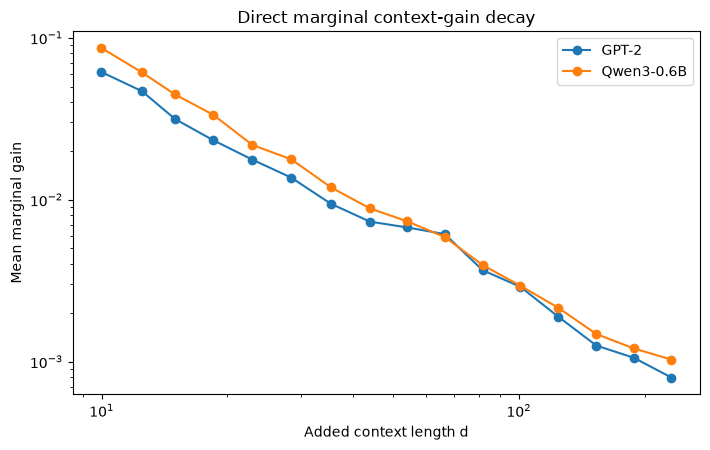

In [18]:
fig, ax = plt.subplots(figsize=(7.2, 4.6))

for scorer, g in binned.groupby("scorer"):
    q = g[g["mean_marginal"] > 0]

    ax.plot(
        q["d_mid"],
        q["mean_marginal"],
        marker="o",
        label=scorer,
    )

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Added context length d")
ax.set_ylabel("Mean marginal gain")
ax.set_title("Direct marginal context-gain decay")
ax.legend()
fig.tight_layout()

fig.savefig(
    FIGURES / "clp_direct_marginal_powerlaw.pdf",
    bbox_inches="tight"
)
plt.show()

In [19]:
N_BOOT = 2000
BOOT_SEED = 2020
N_BINS = 16

def direct_alpha_from_matrix(M):
    edges = np.geomspace(
        DISTANCES.min(),
        DISTANCES.max() + 1,
        N_BINS + 1,
    )

    mean_m = M.mean(axis=0)

    xs = []
    ys = []

    for i in range(N_BINS):
        mask = (
            (DISTANCES >= edges[i]) &
            (DISTANCES < edges[i + 1])
        )

        if not mask.any():
            continue

        d_mid = np.exp(
            np.mean(np.log(DISTANCES[mask]))
        )

        y = mean_m[mask].mean()

        if y > 0:
            xs.append(np.log(d_mid))
            ys.append(np.log(y))

    xs = np.asarray(xs)
    ys = np.asarray(ys)

    slope, intercept = np.polyfit(xs, ys, 1)

    pred = intercept + slope * xs
    ss_res = np.square(ys - pred).sum()
    ss_tot = np.square(ys - ys.mean()).sum()

    return -slope, 1 - ss_res / ss_tot

In [20]:
boot_rows = []

for scorer, pack in matrix_cache.items():
    df = pack["df"].reset_index(drop=True)
    M = pack["M"]

    pair_ids = np.array(sorted(df["pair_id"].unique()))

    # Map each pair_id to its two document rows.
    pair_to_rows = {
        pid: np.where(df["pair_id"].to_numpy() == pid)[0]
        for pid in pair_ids
    }

    rng = np.random.RandomState(BOOT_SEED)

    for b in range(N_BOOT):
        sampled_pairs = rng.choice(
            pair_ids,
            size=len(pair_ids),
            replace=True,
        )

        idx = np.concatenate([
            pair_to_rows[pid]
            for pid in sampled_pairs
        ])

        alpha, r2 = direct_alpha_from_matrix(M[idx])

        boot_rows.append({
            "scorer": scorer,
            "boot": b,
            "alpha": alpha,
            "r2": r2,
        })

boot_alpha = pd.DataFrame(boot_rows)

boot_alpha.to_csv(
    RESULTS / "clp_direct_powerlaw_bootstrap.csv",
    index=False,
)

summary = (
    boot_alpha.groupby("scorer")
    .agg(
        alpha_mean=("alpha", "mean"),
        alpha_lo=("alpha", lambda x: np.quantile(x, 0.025)),
        alpha_hi=("alpha", lambda x: np.quantile(x, 0.975)),
        r2_mean=("r2", "mean"),
        r2_lo=("r2", lambda x: np.quantile(x, 0.025)),
    )
)

display(summary)

,alpha_mean,alpha_lo,alpha_hi,r2_mean,r2_lo
scorer,,,,,
GPT-2,1.351572,1.317841,1.385230,0.991394,0.98747
Qwen3-0.6B,1.425410,1.395920,1.455577,0.996510,0.99392



## Interpretation guide

The following outcomes have different meanings.

### Case A — Marginal matrix is already low rank

If `Marginal` has a small participation ratio and few components explain most
variance, then the scorer's context response itself is well described by a small
number of distance kernels:

\[
m_x(d)\approx\sum_{r=1}^{R}a_{x,r}\kappa_r(d).
\]

This would provide a substantive response-level mathematical explanation for the
CLP compression result.

### Case B — Marginal matrix is high rank but shape is low rank

Then much of notebook 19's low dimensionality is created by the deterministic
integration operator

\[
S=MC.
\]

In that case dense CLP is compressible partly because cumulative context-length
probing is mathematically a strong low-pass/smoothing transform.

### Case C — Observed shape is much lower-dimensional than the permutation null

Then integration alone is insufficient. Cross-distance covariance in the actual
scorer response contributes additional low-dimensional structure.

### Case D — Best power-law exponent is near one and is close to rank-1 SVD quality

Then the log-context geometry has a direct mathematical explanation:

\[
m(d)\propto d^{-1}
\quad\Longrightarrow\quad
S(k)\propto \log(256/k).
\]

If the best exponent is far from one, or the exponential alternative is comparable
or superior, retain the low-rank result but reject the stronger harmonic-kernel
interpretation.

## What this notebook cannot establish

Even a very clean small-\(R\) kernel decomposition does **not** identify \(W_Q\),
\(W_K\), \(W_V\), individual attention heads, or source-generator internals.
Many internal parameterizations can yield the same behavioral response.

A scorer-internal mechanistic notebook is justified only if this notebook reveals a
stable, interpretable response-level kernel structure. The appropriate next test
would then be causal activation/head patching in the open scorer, asking whether a
small set of layers or heads accounts for the recovered long-context response modes.



## Conclusion template

Fill this only after inspecting the outputs.

- **Integration contribution:** [Does the cumulative operator materially reduce
  effective dimension?]
- **Residual response structure:** [Is observed shape lower-dimensional than the
  column-permutation/operator-only null?]
- **Marginal kernel rank:** [How many empirical marginal kernels reconstruct most
  of the dense CLP shape?]
- **Parametric law:** [Best shared \(\alpha\); comparison with \(\alpha=1\),
  exponential decay, and rank-1 SVD.]
- **Cross-scorer agreement:** [Do Qwen and GPT-2 show the same mechanism?]
- **Mechanistic follow-up:** Proceed to scorer-internal attention/activation
  interventions only if a stable response-level kernel is recovered.
